# Show that you can still get rich with the small init

In [15]:
from src import SV_configs
from src import utils
from src import linear_RNN
import numpy as np
import pandas as pd
from types import SimpleNamespace
import matplotlib.pyplot as plt

In [16]:
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

In [17]:
def generate_unaligned_teacher_data(args, variance):  # (one seed)
    X = np.random.normal(0, 0.01, size=(args.num_samples, args.trajectory_length * args.input_size)).astype(float)
    X = utils.whiten(X).reshape(args.num_samples, args.trajectory_length, args.input_size)
    teacher_W_x = np.random.normal(loc=0.0, scale=variance, size=(args.hidden_size, args.input_size))
    teacher_W_h = np.random.normal(loc=0.0, scale=variance, size=(args.hidden_size, args.hidden_size))
    teacher_W_y = np.random.normal(loc=0.0, scale=variance, size=(args.output_size, args.hidden_size))
    h_t = np.zeros((args.num_samples, args.hidden_size))
    h_trajectory = np.zeros((args.num_samples, args.trajectory_length, args.hidden_size))
    for t in range(args.trajectory_length):
        h_t = np.einsum("ij,bj->bi", teacher_W_h, h_t) + np.einsum("ij,bj->bi", teacher_W_x, X[:, t])
    y_t = np.einsum("ij,bj->bi", teacher_W_y, h_t)
    y = y_t.reshape(y_t.shape[0], 1, -1)

    return X, y, teacher_W_x, teacher_W_h, teacher_W_y

In [18]:
def kernel_distance(A, B):
    # Extract matrices K_t1 and K_t2
    K_t1 = A
    K_t2 = B
    # Compute the Frobenius inner product
    inner_product = np.sum(K_t1 * K_t2)
    # Compute the Frobenius norms
    norm_t1 = np.linalg.norm(K_t1, 'fro')
    norm_t2 = np.linalg.norm(K_t2, 'fro')
    # Compute the similarity measure
    S_t1_t2 = 1 - inner_product / (norm_t1 * norm_t2)
    return S_t1_t2

In [19]:
NTK_a = {}
losses = {}
kernel_distances = {}
kernel_distances_seeds = {}
reshaped_NTK_3D_traj_1_seed = {}
traj_1_args = {
            'data_out_dir': 'data/',
            'results_out_dir': 'results/',
            'name': 'unaligned',
            'num_seeds': 1,
            # to run over more seeds which need to be specified as arguments (see simulate.py for example)
            'override_load': False,
            'trajectory_length': 1,
            'num_samples': 50,
            'num_epochs': 30000,
            'lr': 0.01,
            'lmda': -7,
            'initialization_scale': 0.01,
            # (variance of the 0-mean initialized weights when the network is unaligned)
            'input_size': 4,
            'hidden_size': 4,
            'output_size': 4,
            'S_config': ['constant', 'constant', 'constant', 'constant'],
            # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
            'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
            'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
            'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
            'S_TeqS_t': True,
            'relative_initialization': True,
            # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
            'zero_balanced': False,  # if true, sets a=c at initialization (for aligned weights)
            'frozen_hidden_layer': False,  # freezes learning on recurrent layer
            'frozen_input': False,
            'frozen_output': False,# freezes learning on input-output layers
            'single_output_y': True,
            # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
            'inout_mode_init': [0.7, 0.7, 0.7, 0.7],
            # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
            'in_mode_init': [1,1, 1, 1],
            # input mode initialization for each dimension (when input-output weights are not zero-balanced)
            'out_mode_init': [0.7, 0.7, 0.7, 0.7],  # output ""
            'rec_mode_init': [0.1, 0.1, 0.1, 0.1],  # recurrent ""
            'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
            'aligned_student_weights': True,
            'log_H': False,
            'log_y_hat': False,
            'compute_NTK': True,
            'nonlinear_RNN': False,
            'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
            'subsample_NTK': False,  # whether to use a subsample of data when computing NTK
            'single_output_rotation': False,
        }
seed = 0
traj_1_args = SimpleNamespace(**traj_1_args)
traj_1_tape = utils.get_tape_module(traj_1_args)
traj_1_data_tape = utils.get_data_tape(traj_1_args)
utils.set_seeds(seed)
seed_id = 0
## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
#traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
#traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed_id)

## example 2: generating data from a random unaligned teacher (or could be anything else)
traj_1_X, traj_1_y, traj_1_t_W_x, traj_1_t_W_h, traj_1_t_W_y = generate_unaligned_teacher_data(traj_1_args, variance=1)
traj_1_data_tape.X[ seed_id] = traj_1_X
traj_1_data_tape.y[ seed_id] = traj_1_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
#traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed_id, traj_1_tape)
# example 2: unaligned RNN
traj_1_tape = utils.initialize_unaligned_student(traj_1_args, seed_id, traj_1_tape)
# --- model initialization, training, modes, NTK ---
traj_1_model = linear_RNN.LinearRNN_multiseed(traj_1_args, traj_1_tape, seed_id)
traj_1_model.train(traj_1_data_tape.X[seed_id], traj_1_data_tape.y[seed_id])
traj_1_model.project_SVD_space(
    traj_1_data_tape)  # computes modes for aligned network; computes SV for unaligned network
traj_1_model.compute_NTK(traj_1_data_tape.X[seed_id], traj_1_data_tape.y[seed_id], seed_id)
traj_1_tape = traj_1_model.tape
# ntks_empirical[(lmda, scale)] = np.array(
#     [get_ntk(w1w1, w2w2, X, out_dim) for (w1w1, w2w2) in zip(w1w1s_empirical[(lmda, scale)], w2w2s_empirical[(lmda, scale)])])

In [20]:
NTK_a = {}
losses = {}
kernel_distances = {}
kernel_distances_seeds = {}
reshaped_NTK_3D_traj_1_seed = {}
traj_2_args = {
            'data_out_dir': 'data/',
            'results_out_dir': 'results/',
            'name': 'unaligned',
            'num_seeds': 1,
            # to run over more seeds which need to be specified as arguments (see simulate.py for example)
            'override_load': False,
            'trajectory_length': 1,
            'num_samples': 50,
            'num_epochs': 30000,
            'lr': 0.01,
            'lmda': 0,
            'initialization_scale': 0.01,
            # (variance of the 0-mean initialized weights when the network is unaligned)
            'input_size': 4,
            'hidden_size': 4,
            'output_size': 4,
            'S_config': ['constant', 'constant', 'constant', 'constant'],
            # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
            'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
            'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
            'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
            'S_TeqS_t': True,
            'relative_initialization': True,
            # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
            'zero_balanced': False,  # if true, sets a=c at initialization (for aligned weights)
            'frozen_hidden_layer': False,  # freezes learning on recurrent layer
            'frozen_input': False,
            'frozen_output': False,# freezes learning on input-output layers
            'single_output_y': True,
            # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
            'inout_mode_init': [0.7, 0.7, 0.7, 0.7],
            # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
            'in_mode_init': [1,1, 1, 1],
            # input mode initialization for each dimension (when input-output weights are not zero-balanced)
            'out_mode_init': [0.7, 0.7, 0.7, 0.7],  # output ""
            'rec_mode_init': [0.1, 0.1, 0.1, 0.1],  # recurrent ""
            'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
            'aligned_student_weights': True,
            'log_H': False,
            'log_y_hat': False,
            'compute_NTK': True,
            'nonlinear_RNN': False,
            'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
            'subsample_NTK': False,  # whether to use a subsample of data when computing NTK
            'single_output_rotation': False,
        }
seed = 0
traj_2_args = SimpleNamespace(**traj_2_args)
traj_2_tape = utils.get_tape_module(traj_2_args)
traj_2_data_tape = utils.get_data_tape(traj_2_args)
utils.set_seeds(seed)
seed_id = 0
## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
#traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
#traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed_id)

## example 2: generating data from a random unaligned teacher (or could be anything else)
traj_2_X, traj_2_y, traj_2_t_W_x, traj_2_t_W_h, traj_2_t_W_y = generate_unaligned_teacher_data(traj_2_args, variance=1)
traj_2_data_tape.X[ seed_id] = traj_2_X
traj_2_data_tape.y[ seed_id] = traj_2_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
#traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed_id, traj_1_tape)
# example 2: unaligned RNN
traj_2_tape = utils.initialize_unaligned_student(traj_2_args, seed_id, traj_2_tape)
# --- model initialization, training, modes, NTK ---
traj_2_model = linear_RNN.LinearRNN_multiseed(traj_2_args, traj_2_tape, seed_id)
traj_2_model.train(traj_2_data_tape.X[seed_id], traj_2_data_tape.y[seed_id])
traj_2_model.project_SVD_space(
    traj_2_data_tape)  # computes modes for aligned network; computes SV for unaligned network
traj_2_model.compute_NTK(traj_2_data_tape.X[seed_id], traj_2_data_tape.y[seed_id], seed_id)
traj_2_tape = traj_2_model.tape


In [21]:
NTK_a = {}
losses = {}
kernel_distances = {}
kernel_distances_seeds = {}
reshaped_NTK_3D_traj_5_seed = {}
traj_5_args = {
            'data_out_dir': 'data/',
            'results_out_dir': 'results/',
            'name': 'unaligned',
            'num_seeds': 1,
            # to run over more seeds which need to be specified as arguments (see simulate.py for example)
            'override_load': False,
            'trajectory_length': 1,
            'num_samples': 50,
            'num_epochs': 30000,
            'lr': 0.01,
            'lmda': 7,
            'initialization_scale': 0.01,
            # (variance of the 0-mean initialized weights when the network is unaligned)
            'input_size': 4,
            'hidden_size': 4,
            'output_size': 4,
            'S_config': ['constant', 'constant', 'constant', 'constant'],
            # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
            'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
            'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
            'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
            'S_TeqS_t': True,
            'relative_initialization': True,
            # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
            'zero_balanced': False,  # if true, sets a=c at initialization (for aligned weights)
            'frozen_hidden_layer': False,  # freezes learning on recurrent layer
            'frozen_input': False,
            'frozen_output': False,# freezes learning on input-output layers
            'single_output_y': True,
            # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
            'inout_mode_init': [0.7, 0.7, 0.7, 0.7],
            # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
            'in_mode_init': [1,1, 1, 1],
            # input mode initialization for each dimension (when input-output weights are not zero-balanced)
            'out_mode_init': [0.7, 0.7, 0.7, 0.7],  # output ""
            'rec_mode_init': [0.1, 0.1, 0.1, 0.1],  # recurrent ""
            'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
            'aligned_student_weights': True,
            'log_H': False,
            'log_y_hat': False,
            'compute_NTK': True,
            'nonlinear_RNN': False,
            'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
            'subsample_NTK': False,  # whether to use a subsample of data when computing NTK
            'single_output_rotation': False,
        }
seed = 0
traj_5_args = SimpleNamespace(**traj_5_args)
traj_5_tape = utils.get_tape_module(traj_5_args)
traj_5_data_tape = utils.get_data_tape(traj_5_args)
utils.set_seeds(seed)
seed_id = 0
## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
#traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
#traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed_id)

## example 2: generating data from a random unaligned teacher (or could be anything else)
traj_5_X, traj_5_y, traj_5_t_W_x, traj_5_t_W_h, traj_5_t_W_y = generate_unaligned_teacher_data(traj_5_args, variance=1)
traj_5_data_tape.X[ seed_id] = traj_5_X
traj_5_data_tape.y[ seed_id] = traj_5_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
#traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed_id, traj_1_tape)
# example 2: unaligned RNN
traj_5_tape = utils.initialize_unaligned_student(traj_5_args, seed_id, traj_5_tape)
# --- model initialization, training, modes, NTK ---
traj_5_model = linear_RNN.LinearRNN_multiseed(traj_5_args, traj_5_tape, seed_id)
traj_5_model.train(traj_5_data_tape.X[seed_id], traj_5_data_tape.y[seed_id])
traj_5_model.project_SVD_space(
    traj_5_data_tape)  # computes modes for aligned network; computes SV for unaligned network
traj_5_model.compute_NTK(traj_5_data_tape.X[seed_id], traj_5_data_tape.y[seed_id], seed_id)
traj_5_tape = traj_5_model.tape


/var/folders/lk/fjxx3prd2h31kn1cfccrk8fc0000gq/T/ipykernel_61839/4092236377.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axd['i'].legend(frameon=False, bbox_to_anchor=(1, 0.5))
/var/folders/lk/fjxx3prd2h31kn1cfccrk8fc0000gq/T/ipykernel_61839/4092236377.py:55: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


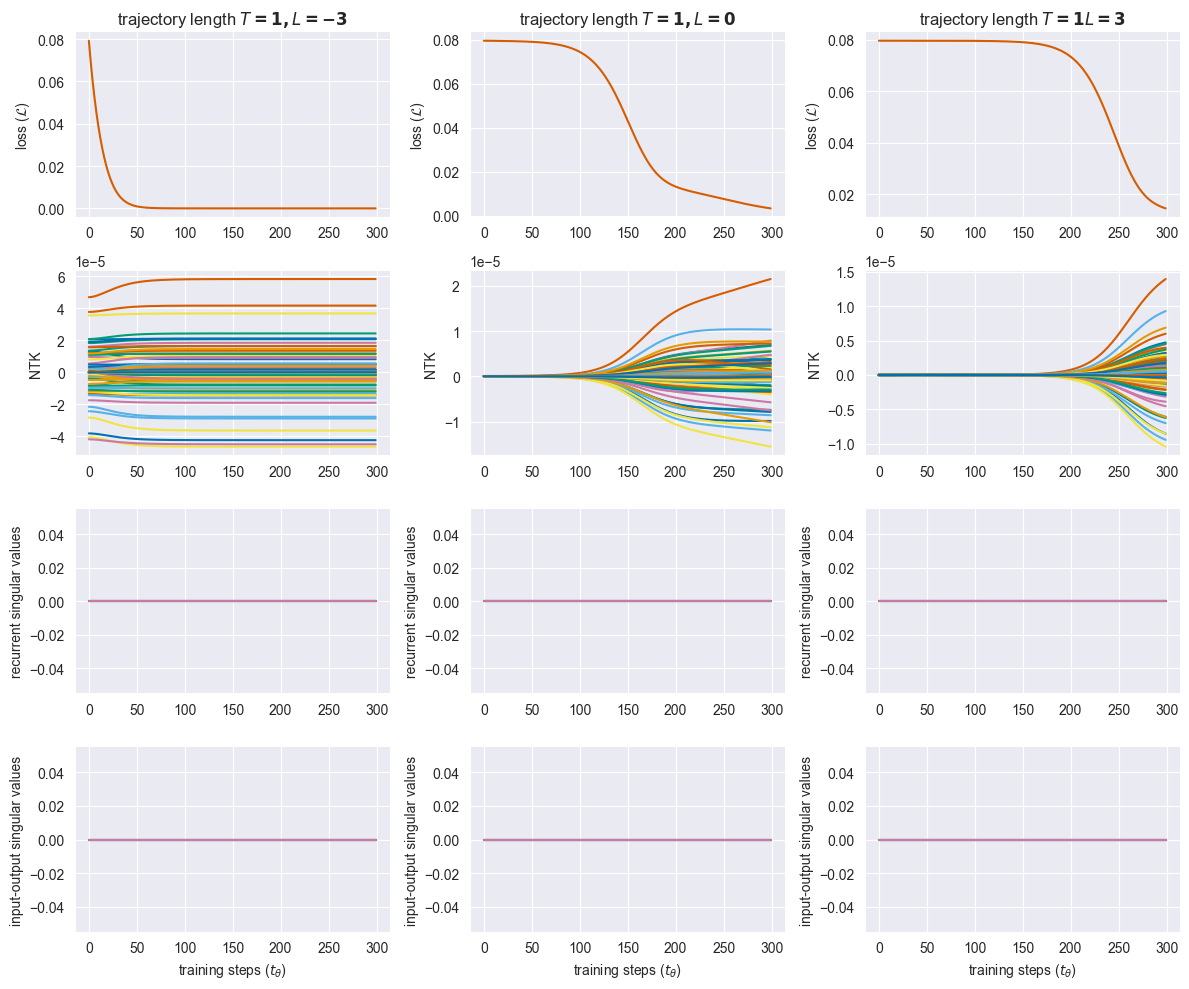

In [22]:
fig = plt.figure(figsize=(12,10), layout='constrained')
mosaic = """
abc
def
ghi
jkl
"""

axd = fig.subplot_mosaic(mosaic)
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_prop_cycle('color', blind_colors[:-1])

axd['a'].plot(traj_1_tape.loss[seed], color=blind_colors[0])
axd['a'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['a'].set_title(r'trajectory length $T= 1, L= -3$')
axd['b'].plot(traj_2_tape.loss[seed], color=blind_colors[0])
axd['b'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['b'].set_title(r'trajectory length $T= 1, L= 0$')
axd['c'].plot(traj_5_tape.loss[seed], color=blind_colors[0])
axd['c'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['c'].set_title(r'trajectory length $T= 1 L=3 $')

axd['d'].plot(traj_1_tape.NTK[seed].reshape(int(traj_1_args.num_epochs/traj_1_args.log_every_e_epoch), traj_1_args.num_samples*traj_1_args.output_size*traj_1_args.num_samples*traj_1_args.output_size)[:,:100])
axd['d'].set_ylabel('NTK')
axd['e'].plot(traj_2_tape.NTK[seed].reshape(int(traj_2_args.num_epochs/traj_2_args.log_every_e_epoch), traj_2_args.num_samples*traj_2_args.output_size*traj_2_args.num_samples*traj_2_args.output_size)[:,:100])
axd['e'].set_ylabel('NTK')
axd['f'].plot(traj_5_tape.NTK[seed].reshape(int(traj_5_args.num_epochs/traj_5_args.log_every_e_epoch), traj_5_args.num_samples*traj_5_args.output_size*traj_5_args.num_samples*traj_5_args.output_size)[:,:100])
axd['f'].set_ylabel('NTK')

axd['g'].plot(traj_1_tape.recurrent_modes[seed])
axd['g'].set_ylabel(r'recurrent singular values')
# axd['h'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['h'].plot(traj_2_tape.recurrent_modes[seed])
axd['h'].set_ylabel(r'recurrent singular values')
# axd['i'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['i'].plot(traj_5_tape.recurrent_modes[seed])
axd['i'].set_ylabel(r'recurrent singular values')
axd['i'].legend(frameon=False, bbox_to_anchor=(1, 0.5))

# axd['j'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['j'].plot(traj_1_tape.input_output_modes[seed])
axd['j'].set_ylabel(r'input-output singular values')
axd['j'].set_xlabel(r'training steps ($t_\theta$)')
# axd['k'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['k'].plot(traj_2_tape.input_output_modes[seed])
axd['k'].set_ylabel(r'input-output singular values')
axd['k'].set_xlabel(r'training steps ($t_\theta$)')
# axd['l'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['l'].plot(traj_5_tape.input_output_modes[seed])
axd['l'].set_ylabel(r'input-output singular values')
axd['l'].set_xlabel(r'training steps ($t_\theta$)')

fig.tight_layout()
# fig.savefig('paper_figs/rich_lazy_constant.svg', dpi=300, transparent=True)
# fig.savefig('paper_figs/rich_lazy_constant.png', dpi=300, transparent=True)

/var/folders/lk/fjxx3prd2h31kn1cfccrk8fc0000gq/T/ipykernel_61839/4068163398.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axd['i'].legend(frameon=False, bbox_to_anchor=(1, 0.5))


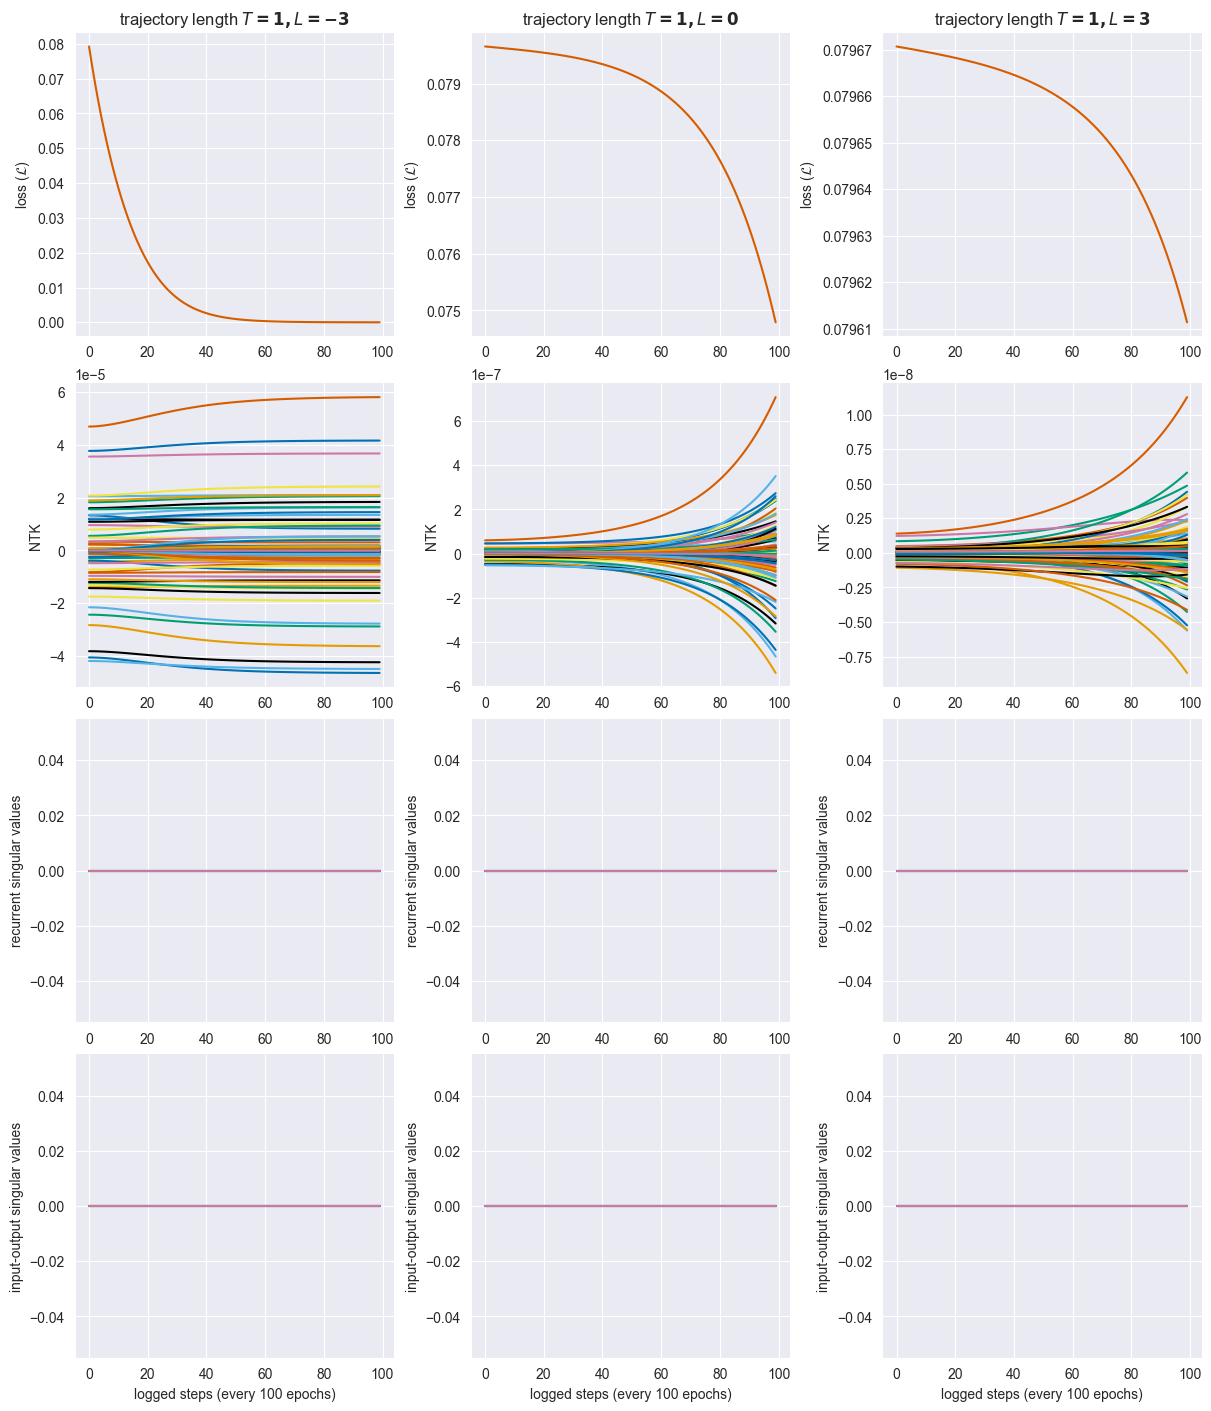

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Setup Figure and Mosaic ---
fig = plt.figure(figsize=(12, 14), layout='constrained')
mosaic = """
abc
def
ghi
jkl
"""
axd = fig.subplot_mosaic(mosaic)

# Assuming blind_colors is defined (e.g., blind_colors = ['#0072B2', '#D55E00', ...])
# Styling the axes
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_prop_cycle('color', blind_colors)

# Configuration for slicing
# Since you logged every 100 epochs, [:100] represents the first 10,000 epochs.
idx = 0
limit = 100

# --- 2. Row 1: Loss ---
axd['a'].plot(traj_1_tape.loss[idx][:limit], color=blind_colors[0])
axd['a'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['a'].set_title(r'trajectory length $T=1, L=-3$')

axd['b'].plot(traj_2_tape.loss[idx][:limit], color=blind_colors[0])
axd['b'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['b'].set_title(r'trajectory length $T=1, L=0$')

axd['c'].plot(traj_5_tape.loss[idx][:limit], color=blind_colors[0])
axd['c'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['c'].set_title(r'trajectory length $T=1, L=3$')

# --- 3. Row 2: NTK ---
# Reshaping automatically based on the data provided
# We slice [:limit] on time (rows) and [:100] on features (columns)
axd['d'].plot(traj_1_tape.NTK[idx].reshape(traj_1_tape.NTK[idx].shape[0], -1)[:limit, :100])
axd['d'].set_ylabel('NTK')

axd['e'].plot(traj_2_tape.NTK[idx].reshape(traj_2_tape.NTK[idx].shape[0], -1)[:limit, :100])
axd['e'].set_ylabel('NTK')

axd['f'].plot(traj_5_tape.NTK[idx].reshape(traj_5_tape.NTK[idx].shape[0], -1)[:limit, :100])
axd['f'].set_ylabel('NTK')

# --- 4. Row 3: Recurrent Singular Values ---
axd['g'].plot(traj_1_tape.recurrent_modes[idx][:limit])
axd['g'].set_ylabel(r'recurrent singular values')

axd['h'].plot(traj_2_tape.recurrent_modes[idx][:limit])
axd['h'].set_ylabel(r'recurrent singular values')

axd['i'].plot(traj_5_tape.recurrent_modes[idx][:limit])
axd['i'].set_ylabel(r'recurrent singular values')
axd['i'].legend(frameon=False, bbox_to_anchor=(1, 0.5))

# --- 5. Row 4: Input-Output Singular Values ---
axd['j'].plot(traj_1_tape.input_output_modes[idx][:limit])
axd['j'].set_ylabel(r'input-output singular values')
axd['j'].set_xlabel(r'logged steps (every 100 epochs)')

axd['k'].plot(traj_2_tape.input_output_modes[idx][:limit])
axd['k'].set_ylabel(r'input-output singular values')
axd['k'].set_xlabel(r'logged steps (every 100 epochs)')

axd['l'].plot(traj_5_tape.input_output_modes[idx][:limit])
axd['l'].set_ylabel(r'input-output singular values')
axd['l'].set_xlabel(r'logged steps (every 100 epochs)')

# Final layout adjustment
# Note: layout='constrained' in the figure call replaces tight_layout()
plt.show()

In [25]:
NTK_a = {}
losses = {}
kernel_distances = {}
kernel_distances_seeds = {}
reshaped_NTK_3D_traj_1_seed = {}
traj_1_args = {
            'data_out_dir': 'data/',
            'results_out_dir': 'results/',
            'name': 'unaligned',
            'num_seeds': 1,
            # to run over more seeds which need to be specified as arguments (see simulate.py for example)
            'override_load': False,
            'trajectory_length': 2,
            'num_samples': 50,
            'num_epochs': 30000,
            'lr': 0.01,
            'lmda': -15,
            'initialization_scale': 0.01,
            # (variance of the 0-mean initialized weights when the network is unaligned)
            'input_size': 4,
            'hidden_size': 4,
            'output_size': 4,
            'S_config': ['constant', 'constant', 'constant', 'constant'],
            # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
            'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
            'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
            'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
            'S_TeqS_t': True,
            'relative_initialization': True,
            # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
            'zero_balanced': False,  # if true, sets a=c at initialization (for aligned weights)
            'frozen_hidden_layer': False,  # freezes learning on recurrent layer
            'frozen_input': False,
            'frozen_output': False,# freezes learning on input-output layers
            'single_output_y': True,
            # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
            'inout_mode_init': [0.7, 0.7, 0.7, 0.7],
            # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
            'in_mode_init': [1,1, 1, 1],
            # input mode initialization for each dimension (when input-output weights are not zero-balanced)
            'out_mode_init': [0.7, 0.7, 0.7, 0.7],  # output ""
            'rec_mode_init': [0.1, 0.1, 0.1, 0.1],  # recurrent ""
            'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
            'aligned_student_weights': True,
            'log_H': False,
            'log_y_hat': False,
            'compute_NTK': True,
            'nonlinear_RNN': False,
            'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
            'subsample_NTK': False,  # whether to use a subsample of data when computing NTK
            'single_output_rotation': False,
        }
seed = 0
traj_1_args = SimpleNamespace(**traj_1_args)
traj_1_tape = utils.get_tape_module(traj_1_args)
traj_1_data_tape = utils.get_data_tape(traj_1_args)
utils.set_seeds(seed)
seed_id = 0
## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
#traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
#traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed_id)

## example 2: generating data from a random unaligned teacher (or could be anything else)
traj_1_X, traj_1_y, traj_1_t_W_x, traj_1_t_W_h, traj_1_t_W_y = generate_unaligned_teacher_data(traj_1_args, variance=1)
traj_1_data_tape.X[ seed_id] = traj_1_X
traj_1_data_tape.y[ seed_id] = traj_1_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
#traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed_id, traj_1_tape)
# example 2: unaligned RNN
traj_1_tape = utils.initialize_unaligned_student(traj_1_args, seed_id, traj_1_tape)
# --- model initialization, training, modes, NTK ---
traj_1_model = linear_RNN.LinearRNN_multiseed(traj_1_args, traj_1_tape, seed_id)
traj_1_model.train(traj_1_data_tape.X[seed_id], traj_1_data_tape.y[seed_id])
traj_1_model.project_SVD_space(
    traj_1_data_tape)  # computes modes for aligned network; computes SV for unaligned network
traj_1_model.compute_NTK(traj_1_data_tape.X[seed_id], traj_1_data_tape.y[seed_id], seed_id)
traj_1_tape = traj_1_model.tape


In [28]:
NTK_a = {}
losses = {}
kernel_distances = {}
kernel_distances_seeds = {}
reshaped_NTK_3D_traj_1_seed = {}
traj_2_args = {
            'data_out_dir': 'data/',
            'results_out_dir': 'results/',
            'name': 'unaligned',
            'num_seeds': 1,
            # to run over more seeds which need to be specified as arguments (see simulate.py for example)
            'override_load': False,
            'trajectory_length': 2,
            'num_samples': 50,
            'num_epochs': 30000,
            'lr': 0.01,
            'lmda': 0,
            'initialization_scale': 0.01,
            # (variance of the 0-mean initialized weights when the network is unaligned)
            'input_size': 4,
            'hidden_size': 4,
            'output_size': 4,
            'S_config': ['constant', 'constant', 'constant', 'constant'],
            # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
            'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
            'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
            'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
            'S_TeqS_t': True,
            'relative_initialization': True,
            # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
            'zero_balanced': False,  # if true, sets a=c at initialization (for aligned weights)
            'frozen_hidden_layer': False,  # freezes learning on recurrent layer
            'frozen_input': False,
            'frozen_output': False,# freezes learning on input-output layers
            'single_output_y': True,
            # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
            'inout_mode_init': [0.7, 0.7, 0.7, 0.7],
            # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
            'in_mode_init': [1,1, 1, 1],
            # input mode initialization for each dimension (when input-output weights are not zero-balanced)
            'out_mode_init': [0.7, 0.7, 0.7, 0.7],  # output ""
            'rec_mode_init': [0.1, 0.1, 0.1, 0.1],  # recurrent ""
            'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
            'aligned_student_weights': True,
            'log_H': False,
            'log_y_hat': False,
            'compute_NTK': True,
            'nonlinear_RNN': False,
            'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
            'subsample_NTK': False,  # whether to use a subsample of data when computing NTK
            'single_output_rotation': False,
        }
seed = 0
traj_2_args = SimpleNamespace(**traj_2_args)
traj_2_tape = utils.get_tape_module(traj_2_args)
traj_2_data_tape = utils.get_data_tape(traj_2_args)
utils.set_seeds(seed)
seed_id = 0
## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
#traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
#traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed_id)

## example 2: generating data from a random unaligned teacher (or could be anything else)
traj_2_X, traj_2_y, traj_2_t_W_x, traj_2_t_W_h, traj_2_t_W_y = generate_unaligned_teacher_data(traj_2_args, variance=1)
traj_2_data_tape.X[ seed_id] = traj_2_X
traj_2_data_tape.y[ seed_id] = traj_2_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
#traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed_id, traj_1_tape)
# example 2: unaligned RNN
traj_2_tape = utils.initialize_unaligned_student(traj_2_args, seed_id, traj_2_tape)
# --- model initialization, training, modes, NTK ---
traj_2_model = linear_RNN.LinearRNN_multiseed(traj_2_args, traj_2_tape, seed_id)
traj_2_model.train(traj_2_data_tape.X[seed_id], traj_2_data_tape.y[seed_id])
traj_2_model.project_SVD_space(
    traj_2_data_tape)  # computes modes for aligned network; computes SV for unaligned network
traj_2_model.compute_NTK(traj_2_data_tape.X[seed_id], traj_2_data_tape.y[seed_id], seed_id)
traj_2_tape = traj_2_model.tape
# ntks_empirical[(lmda, scale)] = np.array(
#     [get_ntk(w1w1, w2w2, X, out_dim) for (w1w1, w2w2) in zip(w1w1s_empirical[(lmda, scale)], w2w2s_empirical[(lmda, scale)])])

In [29]:
NTK_a = {}
losses = {}
kernel_distances = {}
kernel_distances_seeds = {}
reshaped_NTK_3D_traj_5_seed = {}
NTK_a = {}
losses = {}
kernel_distances = {}
kernel_distances_seeds = {}
reshaped_NTK_3D_traj_1_seed = {}
traj_5_args = {
            'data_out_dir': 'data/',
            'results_out_dir': 'results/',
            'name': 'unaligned',
            'num_seeds': 1,
            # to run over more seeds which need to be specified as arguments (see simulate.py for example)
            'override_load': False,
            'trajectory_length': 2,
            'num_samples': 50,
            'num_epochs': 30000,
            'lr': 0.01,
            'lmda': 15,
            'initialization_scale': 0.01,
            # (variance of the 0-mean initialized weights when the network is unaligned)
            'input_size': 4,
            'hidden_size': 4,
            'output_size': 4,
            'S_config': ['constant', 'constant', 'constant', 'constant'],
            # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
            'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
            'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
            'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
            'S_TeqS_t': True,
            'relative_initialization': True,
            # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
            'zero_balanced': False,  # if true, sets a=c at initialization (for aligned weights)
            'frozen_hidden_layer': False,  # freezes learning on recurrent layer
            'frozen_input': False,
            'frozen_output': False,# freezes learning on input-output layers
            'single_output_y': True,
            # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
            'inout_mode_init': [0.7, 0.7, 0.7, 0.7],
            # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
            'in_mode_init': [1,1, 1, 1],
            # input mode initialization for each dimension (when input-output weights are not zero-balanced)
            'out_mode_init': [0.7, 0.7, 0.7, 0.7],  # output ""
            'rec_mode_init': [0.1, 0.1, 0.1, 0.1],  # recurrent ""
            'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
            'aligned_student_weights': True,
            'log_H': False,
            'log_y_hat': False,
            'compute_NTK': True,
            'nonlinear_RNN': False,
            'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
            'subsample_NTK': False,  # whether to use a subsample of data when computing NTK
            'single_output_rotation': False,
        }
seed = 0
seed = 0
traj_5_args = SimpleNamespace(**traj_5_args)
traj_5_tape = utils.get_tape_module(traj_5_args)
traj_5_data_tape = utils.get_data_tape(traj_5_args)
utils.set_seeds(seed)
seed_id = 0
## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
#traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
#traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed_id)

## example 2: generating data from a random unaligned teacher (or could be anything else)
traj_5_X, traj_5_y, traj_5_t_W_x, traj_5_t_W_h, traj_5_t_W_y = generate_unaligned_teacher_data(traj_5_args, variance=1)
traj_5_data_tape.X[ seed_id] = traj_5_X
traj_5_data_tape.y[ seed_id] = traj_5_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
#traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed_id, traj_1_tape)
# example 2: unaligned RNN
traj_5_tape = utils.initialize_unaligned_student(traj_5_args, seed_id, traj_5_tape)
# --- model initialization, training, modes, NTK ---
traj_5_model = linear_RNN.LinearRNN_multiseed(traj_5_args, traj_5_tape, seed_id)
traj_5_model.train(traj_5_data_tape.X[seed_id], traj_5_data_tape.y[seed_id])
traj_5_model.project_SVD_space(
    traj_5_data_tape)  # computes modes for aligned network; computes SV for unaligned network
traj_5_model.compute_NTK(traj_5_data_tape.X[seed_id], traj_5_data_tape.y[seed_id], seed_id)
traj_5_tape = traj_5_model.tape
# ntks_empirical[(lmda, scale)] = np.array(
#     [get_ntk(w1w1, w2w2, X, out_dim) for (w1w1, w2w2) in zip(w1w1s_empirical[(lmda, scale)], w2w2s_empirical[(lmda, scale)])])

/var/folders/lk/fjxx3prd2h31kn1cfccrk8fc0000gq/T/ipykernel_61839/3782703548.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axd['i'].legend(frameon=False, bbox_to_anchor=(1, 0.5))
/var/folders/lk/fjxx3prd2h31kn1cfccrk8fc0000gq/T/ipykernel_61839/3782703548.py:55: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


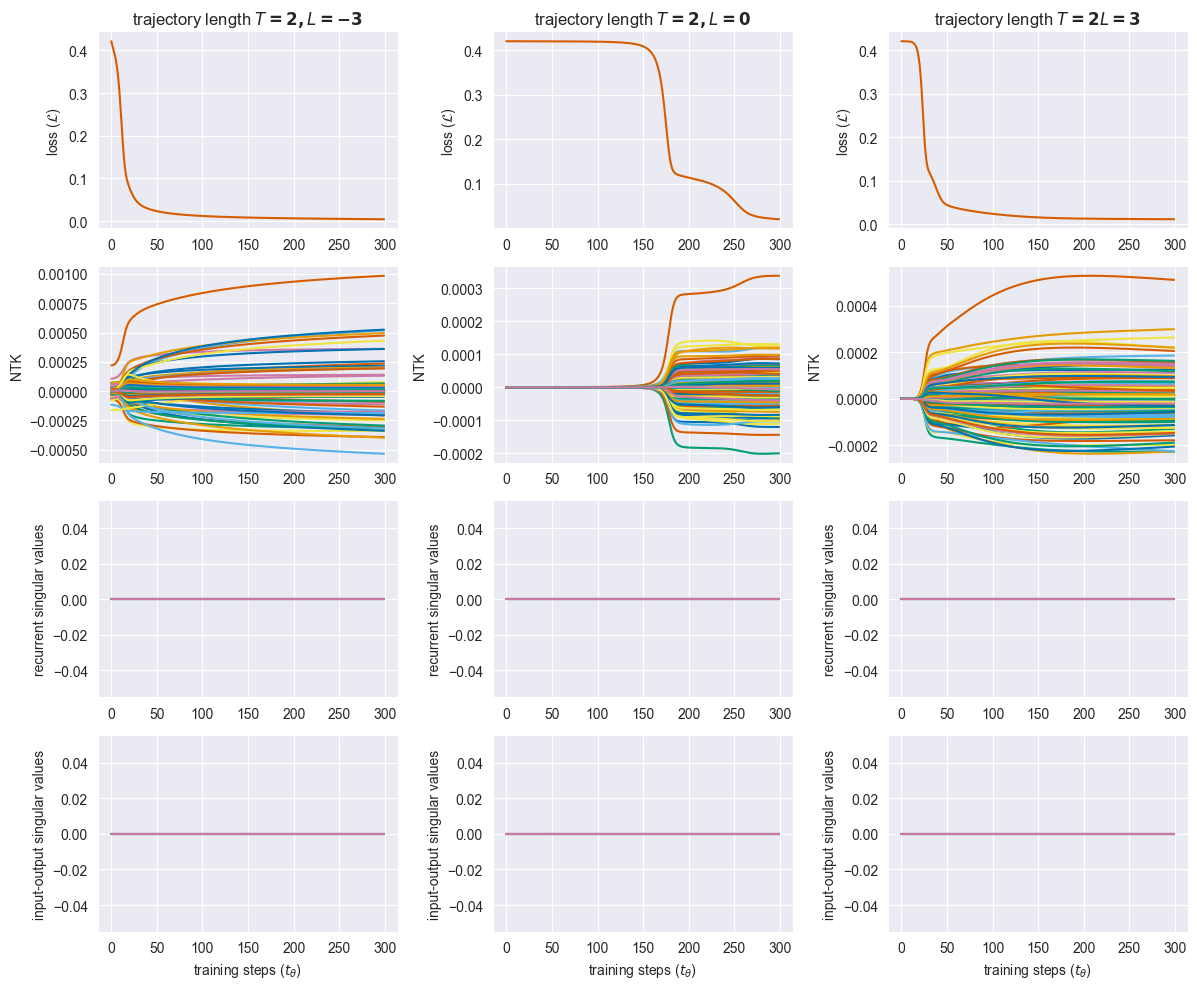

In [30]:
fig = plt.figure(figsize=(12,10), layout='constrained')
mosaic = """
abc
def
ghi
jkl
"""

axd = fig.subplot_mosaic(mosaic)
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_prop_cycle('color', blind_colors[:-1])

axd['a'].plot(traj_1_tape.loss[seed], color=blind_colors[0])
axd['a'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['a'].set_title(r'trajectory length $T= 2, L= -3$')
axd['b'].plot(traj_2_tape.loss[seed], color=blind_colors[0])
axd['b'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['b'].set_title(r'trajectory length $T= 2, L= 0$')
axd['c'].plot(traj_5_tape.loss[seed], color=blind_colors[0])
axd['c'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['c'].set_title(r'trajectory length $T= 2 L=3 $')

axd['d'].plot(traj_1_tape.NTK[seed].reshape(int(traj_1_args.num_epochs/traj_1_args.log_every_e_epoch), traj_1_args.num_samples*traj_1_args.output_size*traj_1_args.num_samples*traj_1_args.output_size)[:,:200])
axd['d'].set_ylabel('NTK')
axd['e'].plot(traj_2_tape.NTK[seed].reshape(int(traj_2_args.num_epochs/traj_2_args.log_every_e_epoch), traj_2_args.num_samples*traj_2_args.output_size*traj_2_args.num_samples*traj_2_args.output_size)[:,:200])
axd['e'].set_ylabel('NTK')
axd['f'].plot(traj_5_tape.NTK[seed].reshape(int(traj_5_args.num_epochs/traj_5_args.log_every_e_epoch), traj_5_args.num_samples*traj_5_args.output_size*traj_5_args.num_samples*traj_5_args.output_size)[:,:200])
axd['f'].set_ylabel('NTK')

axd['g'].plot(traj_1_tape.recurrent_modes[seed])
axd['g'].set_ylabel(r'recurrent singular values')
# axd['h'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['h'].plot(traj_2_tape.recurrent_modes[seed])
axd['h'].set_ylabel(r'recurrent singular values')
# axd['i'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['i'].plot(traj_5_tape.recurrent_modes[seed])
axd['i'].set_ylabel(r'recurrent singular values')
axd['i'].legend(frameon=False, bbox_to_anchor=(1, 0.5))

# axd['j'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['j'].plot(traj_1_tape.input_output_modes[seed])
axd['j'].set_ylabel(r'input-output singular values')
axd['j'].set_xlabel(r'training steps ($t_\theta$)')
# axd['k'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['k'].plot(traj_2_tape.input_output_modes[seed])
axd['k'].set_ylabel(r'input-output singular values')
axd['k'].set_xlabel(r'training steps ($t_\theta$)')
# axd['l'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['l'].plot(traj_5_tape.input_output_modes[seed])
axd['l'].set_ylabel(r'input-output singular values')
axd['l'].set_xlabel(r'training steps ($t_\theta$)')

fig.tight_layout()
# fig.savefig('paper_figs/rich_lazy_constant.svg', dpi=300, transparent=True)
# fig.savefig('paper_figs/rich_lazy_constant.png', dpi=300, transparent=True)

/var/folders/lk/fjxx3prd2h31kn1cfccrk8fc0000gq/T/ipykernel_61839/4068163398.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axd['i'].legend(frameon=False, bbox_to_anchor=(1, 0.5))


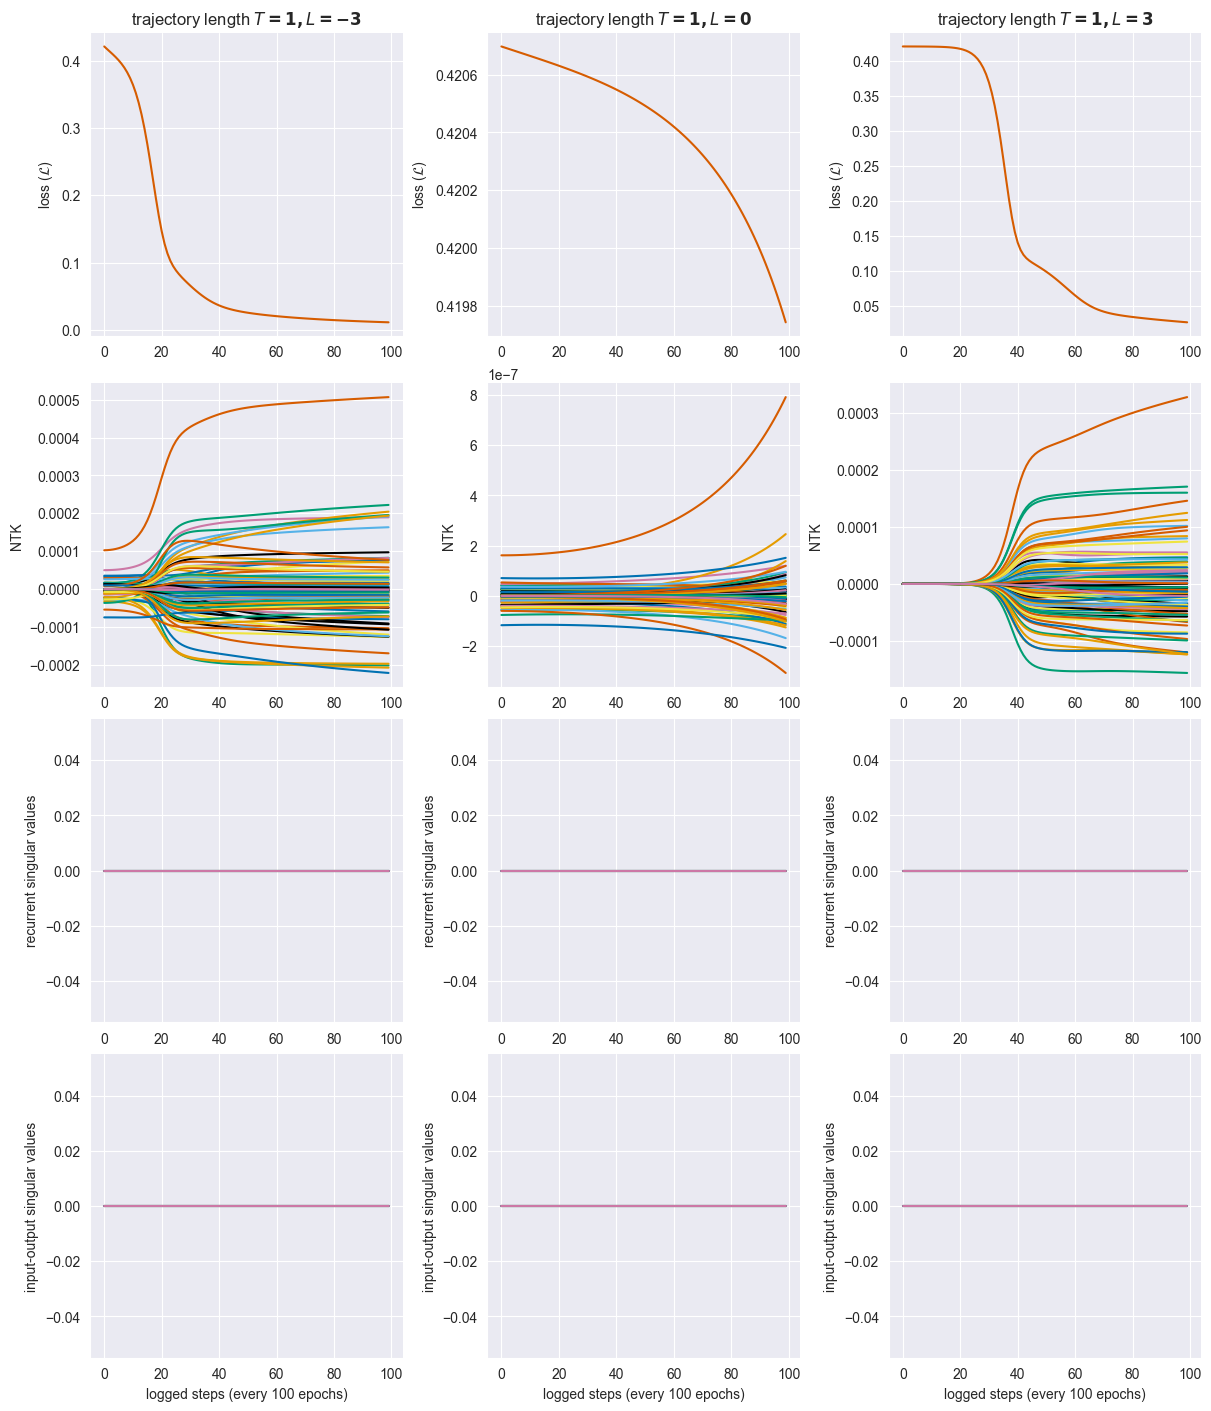

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Setup Figure and Mosaic ---
fig = plt.figure(figsize=(12, 14), layout='constrained')
mosaic = """
abc
def
ghi
jkl
"""
axd = fig.subplot_mosaic(mosaic)

# Assuming blind_colors is defined (e.g., blind_colors = ['#0072B2', '#D55E00', ...])
# Styling the axes
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_prop_cycle('color', blind_colors)

# Configuration for slicing
# Since you logged every 100 epochs, [:100] represents the first 10,000 epochs.
idx = 0
limit = 100

# --- 2. Row 1: Loss ---
axd['a'].plot(traj_1_tape.loss[idx][:limit], color=blind_colors[0])
axd['a'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['a'].set_title(r'trajectory length $T=1, L=-3$')

axd['b'].plot(traj_2_tape.loss[idx][:limit], color=blind_colors[0])
axd['b'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['b'].set_title(r'trajectory length $T=1, L=0$')

axd['c'].plot(traj_5_tape.loss[idx][:limit], color=blind_colors[0])
axd['c'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['c'].set_title(r'trajectory length $T=1, L=3$')

# --- 3. Row 2: NTK ---
# Reshaping automatically based on the data provided
# We slice [:limit] on time (rows) and [:100] on features (columns)
axd['d'].plot(traj_1_tape.NTK[idx].reshape(traj_1_tape.NTK[idx].shape[0], -1)[:limit, :100])
axd['d'].set_ylabel('NTK')

axd['e'].plot(traj_2_tape.NTK[idx].reshape(traj_2_tape.NTK[idx].shape[0], -1)[:limit, :100])
axd['e'].set_ylabel('NTK')

axd['f'].plot(traj_5_tape.NTK[idx].reshape(traj_5_tape.NTK[idx].shape[0], -1)[:limit, :100])
axd['f'].set_ylabel('NTK')

# --- 4. Row 3: Recurrent Singular Values ---
axd['g'].plot(traj_1_tape.recurrent_modes[idx][:limit])
axd['g'].set_ylabel(r'recurrent singular values')

axd['h'].plot(traj_2_tape.recurrent_modes[idx][:limit])
axd['h'].set_ylabel(r'recurrent singular values')

axd['i'].plot(traj_5_tape.recurrent_modes[idx][:limit])
axd['i'].set_ylabel(r'recurrent singular values')
axd['i'].legend(frameon=False, bbox_to_anchor=(1, 0.5))

# --- 5. Row 4: Input-Output Singular Values ---
axd['j'].plot(traj_1_tape.input_output_modes[idx][:limit])
axd['j'].set_ylabel(r'input-output singular values')
axd['j'].set_xlabel(r'logged steps (every 100 epochs)')

axd['k'].plot(traj_2_tape.input_output_modes[idx][:limit])
axd['k'].set_ylabel(r'input-output singular values')
axd['k'].set_xlabel(r'logged steps (every 100 epochs)')

axd['l'].plot(traj_5_tape.input_output_modes[idx][:limit])
axd['l'].set_ylabel(r'input-output singular values')
axd['l'].set_xlabel(r'logged steps (every 100 epochs)')

# Final layout adjustment
# Note: layout='constrained' in the figure call replaces tight_layout()
plt.show()